# Notebook 5: Baseline Comparisons on Held-Out Scaffold Benchmark

### Objectives
1. Evaluate PPO Baseline and PPO Adaptive against Random Valid Edits and Greedy Hill Climbing on the exact same 60 test molecules.
2. Compare performance across key metrics: Delta-QED, Normalized Headroom Gain (NHG), Success Rate, Structural Similarity, and SAS change.

In [1]:
import torch
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

root_dir = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.path.abspath('.')
if root_dir not in sys.path:
    sys.path.insert(0, root_dir)

summary_path = os.path.join(root_dir, 'results', 'method_comparison_summary.csv')
df_sum = pd.read_csv(summary_path)
print('=== Benchmark Method Comparison (60 Held-Out Scaffolds) ===')
display(df_sum)

=== Benchmark Method Comparison (60 Held-Out Scaffolds) ===


,method,count,mean_delta_qed,std_delta_qed,mean_nhg,success_rate,validity_rate,mean_similarity,mean_delta_sas,mean_edits,pains_alert_rate,brenk_alert_rate,mean_lipinski_violations,sanity_pass_rate
0,Random Valid Edits,60,-0.432976,0.206609,-2.361947,0.033333,1.0,0.227634,1.951517,9.683333,0.183333,0.983333,0.716667,1.0
1,Greedy Hill Climbing,60,0.109540,0.076691,0.353472,0.566667,1.0,0.598854,0.399992,1.766667,0.066667,0.250000,0.033333,1.0
2,PPO Baseline,60,-0.437593,0.212310,-2.390822,0.050000,1.0,0.264647,1.405827,9.600000,0.166667,0.983333,0.783333,1.0
3,PPO Adaptive (Proposed),60,-0.147742,0.168148,-0.793328,0.050000,1.0,0.494102,0.723200,9.616667,0.033333,0.650000,0.166667,1.0


### 1. Benchmark Comparison Plots
Visualizing Delta-QED, Success Rate, and Tanimoto Structural Similarity preservation.

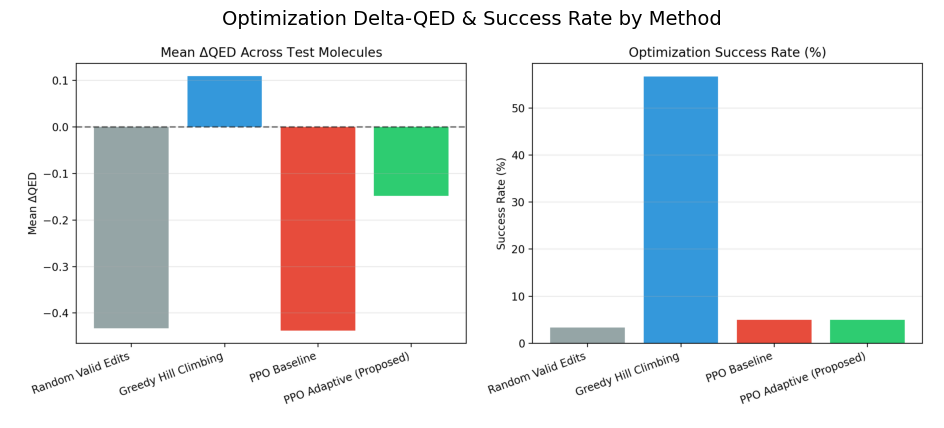

In [2]:
fig_path = os.path.join(root_dir, 'figures', 'evaluation_delta_qed_and_success.png')
if os.path.exists(fig_path):
    img = Image.open(fig_path)
    plt.figure(figsize=(12, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Optimization Delta-QED & Success Rate by Method', fontsize=14)
    plt.show()

### 2. Sample Optimized Molecules
Inspect sample test molecules optimized by PPO Adaptive.

In [3]:
eval_csv = os.path.join(root_dir, 'results', 'final_evaluation_results.csv')
df_eval = pd.read_csv(eval_csv)
sample_df = df_eval[df_eval['method'] == 'PPO Adaptive (Proposed)'].head(5)
display(sample_df[['initial_smiles', 'final_smiles', 'initial_qed', 'final_qed', 'delta_qed', 'similarity', 'success']])

,initial_smiles,final_smiles,initial_qed,final_qed,delta_qed,similarity,success
180,O=C(NCC[NH+]1CCN(C(=O)c2ccccc2[N+](=O)[O-])CC1...,O=C(NCC[NH+]1CCN(C(=O)c2ccccc2[N+](=O)[O-])CO1...,0.443625,0.407287,-0.036338,0.684211,False
181,COc1ccc(-n2c(C)cc(C(=O)CSc3nnc(-c4ccoc4C)n3C)c...,Cc1occc1-c1nnc(SCC(=O)c2cc(C)n(-c3ccc(OC(C)(C)...,0.306715,0.261132,-0.045583,0.680556,False
182,O=C1c2ccccc2C(=O)N1N=Cc1ccc(/C=N/N2C(=O)c3cccc...,C=C1c2nccnc2C(=O)N1N=Cc1ccc(/C=N/N2C(=N)c3cccc...,0.476695,0.629581,0.152886,0.415094,True
183,O=C(CNc1ccc(Cl)cc1NC(=O)c1ccco1)Nc1ccc(F)c(Cl)c1,Cc1ccc(NCC(=O)Nc2ccc(F)c(Cl)c2)c(NC(=O)c2cc(S)...,0.520608,0.413376,-0.107232,0.615385,False
184,O=[N+]([O-])c1ccc(N2CC[NH+](CCO)CC2)c(/C=N/c2c...,O=[N+]([O-])c1ccc(N2C#C[NH+](CCO)CO2)c(/C=N/c2...,0.270271,0.202428,-0.067842,0.554217,False
